<a href="https://colab.research.google.com/github/mdjees/MachineLearning/blob/main/WorldCUP_prediction_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#Importing the libraries first ig, obviously
import pandas as pd
import numpy as np
from collections import defaultdict
import random
import warnings
warnings.filterwarnings('ignore')

In [ ]:
#Now we Set seeds for reproducibility
random.seed(42)
np.random.seed(42)

In [ ]:
# Machine Learning, :)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from xgboost import XGBClassifier

In [ ]:
# Visualization
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
plt.style.use('seaborn-v0_8-darkgrid')

In [ ]:
#Load data
df = pd.read_csv('results.csv')
print(f"   Shape:        {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"   Date range:   {df['date'].min()}  →  {df['date'].max()}")
print(f"   Unique teams: {pd.concat([df['home_team'], df['away_team']]).nunique()}")


   Shape:        49,477 rows × 9 columns
   Date range:   1872-11-30  →  2026-06-27
   Unique teams: 336


In [ ]:
# Explore the data, cause we genz do make a big deal about exploring in general, hence main task begins:)
print("─── First 5 rows ───────────────────────────────")
print(df.head(5).to_string())

print("\n─── Columns & Types ─────────────────────────────")
print(df.dtypes)

print("\n─── Missing Values ──────────────────────────────")
print(df.isnull().sum())

print("\n─── Top 15 Tournaments ──────────────────────────")
print(df['tournament'].value_counts().head(15))

print("\n─── Score distribution ──────────────────────────")
print("Average goals per match (home):", round(df['home_score'].mean(), 2))
print("Average goals per match (away):", round(df['away_score'].mean(), 2))

─── First 5 rows ───────────────────────────────
         date home_team away_team  home_score  away_score tournament     city   country  neutral
0  1872-11-30  Scotland   England         0.0         0.0   Friendly  Glasgow  Scotland    False
1  1873-03-08   England  Scotland         4.0         2.0   Friendly   London   England    False
2  1874-03-07  Scotland   England         2.0         1.0   Friendly  Glasgow  Scotland    False
3  1875-03-06   England  Scotland         2.0         2.0   Friendly   London   England    False
4  1876-03-04  Scotland   England         3.0         0.0   Friendly  Glasgow  Scotland    False

─── Columns & Types ─────────────────────────────
date           object
home_team      object
away_team      object
home_score    float64
away_score    float64
tournament     object
city           object
country        object
neutral          bool
dtype: object

─── Missing Values ──────────────────────────────
date           0
home_team      0
away_team      0
home

In [ ]:
#PRE-PROCESS AND Cleaning of Data
#What exactly we do:  1. Convert date strings → proper datetime objects
  #2. Drop rows with missing scores (rare, but they exist)
 # 3. Handle the 'neutral' column (some datasets don't have it)
  #4. Add a 'result' column so the target variable is clear



In [ ]:
# Convert date column
df['date'] = pd.to_datetime(df['date'])

In [ ]:
# Drop rows with null scores
before = len(df)
df = df.dropna(subset=['home_score', 'away_score'])
df['home_score'] = df['home_score'].astype(int)
df['away_score'] = df['away_score'].astype(int)
print(f"Removed {before - len(df)} rows with missing scores. Remaining: {len(df):,}")

Removed 44 rows with missing scores. Remaining: 49,433


In [ ]:
# Handle 'neutral' column
if 'neutral' not in df.columns:
    df['neutral'] = False
df['neutral'] = df['neutral'].fillna(False).astype(bool)

In [ ]:
# Add result labels
# Numeric: 2=home win, 1=draw, 0=away win
def label_result(row):
    if row['home_score'] > row['away_score']:
        return 2   # home win
    elif row['home_score'] < row['away_score']:
        return 0   # away win
    else:
        return 1   # draw

df['result_num'] = df.apply(label_result, axis=1)
df['result_str'] = df['result_num'].map({2: 'home_win', 1: 'draw', 0: 'away_win'})

In [ ]:
# Sort by date (critical for Elo and feature engineering)
df = df.sort_values('date').reset_index(drop=True)

In [ ]:
print("\nhooraaayyyyy Data cleaned and sorted by date!")
print("\nOverall result split:")
print(df['result_str'].value_counts(normalize=True).round(3))


hooraaayyyyy Data cleaned and sorted by date!

Overall result split:
result_str
home_win    0.490
away_win    0.282
draw        0.227
Name: proportion, dtype: float64


#BUILD ELO RATING SYSTEM
#WHAT IS ELO?
  #(Elo was invented for chess, but it works perfectly for football.
  Every team starts at 1500. You gain points by winning, lose by losing.
  HOW MUCH you gain/lose depends on:
    1. How expected the result was (beating a 400-Elo stronger team = big gain)
    2. How important the match is (World Cup > Friendly)

THE FORMULA:
  Expected score for team A:
    E_A = 1 / (1 + 10 ^ ((R_B - R_A) / 400))

  New rating after match:
    R_A_new = R_A + K × (Actual_Score - Expected_Score)

  Where:
    - E_A = probability of A winning (0 to 1)
    - K   = match importance weight (higher = more impact)
    - Actual_Score: Win=1.0, Draw=0.5, Loss=0.0

EXAMPLE:
  Argentina (1800) vs Jordan (1300)
  E_Argentina = 1 / (1 + 10^((1300-1800)/400)) = 0.969   (96.9% expected!)
  If Argentina wins:  R_new = 1800 + 60×(1.0 - 0.969) = 1801.9  (tiny gain)
  If Jordan wins:     R_new = 1800 + 60×(0.0 - 0.969) = 1741.9  (huge loss!)

K-FACTOR WEIGHTS (the "nerfs and buffs" from the video):

In [ ]:
TOURNAMENT_K = {
    'FIFA World Cup': 60,
    'UEFA Euro': 55,
    'UEFA European Championship': 55,
    'Copa América': 55,
    'Africa Cup of Nations': 50,
    'AFC Asian Cup': 50,
    'FIFA World Cup qualification': 45,
    'UEFA European Championship qualification': 38,
    'AFC Asian Cup qualification': 38,
    'Africa Cup of Nations qualification': 35,
    'Copa América qualification': 35,
    'UEFA Nations League': 30,
    'CONCACAF Gold Cup': 28,
    'Arab Cup': 22,
    'COSAFA Cup': 20,
    'Friendly': 20,
    'default': 28
}

def get_k_factor(tournament_name: str) -> int:
    """Return K-factor for a tournament by partial name matching."""
    for key, k in TOURNAMENT_K.items():
        if key.lower() in str(tournament_name).lower():
            return k
    return TOURNAMENT_K['default']

def expected_score(rating_a: float, rating_b: float) -> float:
    """Expected score (win probability) for team A vs team B."""
    return 1.0 / (1.0 + 10.0 ** ((rating_b - rating_a) / 400.0))

In [ ]:
# Initialize Elo ratings
elo = defaultdict(lambda: 1500)
elo_home_before = []
elo_away_before = []

# Calculate Elo ratings for each match
for i, row in df.iterrows():
    home_team = row['home_team']
    away_team = row['away_team']
    tournament = row['tournament']
    result_num = row['result_num']

    # Get current Elo ratings
    home_elo = elo[home_team]
    away_elo = elo[away_team]

    # Store ratings before the match
    elo_home_before.append(home_elo)
    elo_away_before.append(away_elo)

    # Calculate expected scores
    expected_home = expected_score(home_elo, away_elo)

    # Determine actual score based on match result (for home team)
    actual_home = 0.0
    if result_num == 2:  # home win
        actual_home = 1.0
    elif result_num == 1: # draw
        actual_home = 0.5
    # else (result_num == 0): away win, actual_home = 0.0

    # Get K-factor for the tournament
    k_factor = get_k_factor(tournament)

    # Update Elo ratings
    elo[home_team] = home_elo + k_factor * (actual_home - expected_home)
    elo[away_team] = away_elo + k_factor * ((1 - actual_home) - (1 - expected_home))

# Attach Elo columns to dataframe
df['home_elo_before'] = elo_home_before
df['away_elo_before'] = elo_away_before
df['elo_diff'] = df['home_elo_before'] - df['away_elo_before']

# Final world rankings
elo_rankings = (
    pd.DataFrame([{'Team': t, 'Elo': round(r, 1)} for t, r in elo.items()])
    .sort_values('Elo', ascending=False)
    .reset_index(drop=True)
)
elo_rankings.index += 1

print("\nTop 25 Teams by Elo Rating (current):")
print(elo_rankings.head(25).to_string())


Top 25 Teams by Elo Rating (current):
             Team     Elo
1           Spain  2073.9
2       Argentina  2057.0
3          France  2032.5
4         England  2018.5
5         Germany  1959.1
6        Colombia  1947.6
7          Brazil  1936.5
8         Morocco  1932.9
9     Netherlands  1928.6
10         Mexico  1928.2
11          Japan  1927.7
12       Portugal  1919.1
13         Norway  1903.2
14        Ecuador  1899.7
15         Turkey  1890.7
16      Australia  1887.9
17        Croatia  1871.7
18    Switzerland  1867.0
19        Belgium  1865.5
20  United States  1857.8
21          Italy  1857.6
22        Uruguay  1856.0
23    South Korea  1840.9
24        Austria  1840.0
25         Canada  1834.7


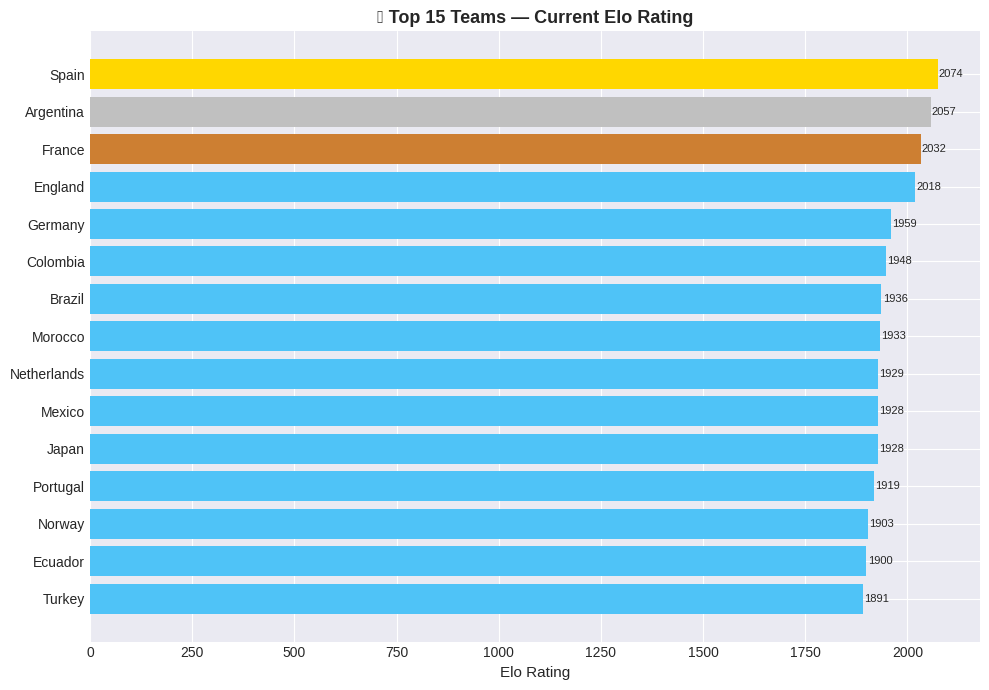

Saved: elo_ratings.png


In [ ]:
# Nowwww we Visualize the mythical Elo ratings!!!!!!!!!
fig, ax = plt.subplots(figsize=(10, 7))
top15 = elo_rankings.head(15)
bar_colors = ['gold', 'silver', '#cd7f32'] + ['#4fc3f7'] * 12
bars = ax.barh(range(len(top15)), top15['Elo'], color=bar_colors)
ax.set_yticks(range(len(top15)))
ax.set_yticklabels(top15['Team'], fontsize=10)
ax.invert_yaxis()
ax.set_xlabel('Elo Rating', fontsize=11)
ax.set_title('⚽ Top 15 Teams — Current Elo Rating', fontsize=13, fontweight='bold')
for i, (bar, val) in enumerate(zip(bars, top15['Elo'])):
    ax.text(bar.get_width() + 3, bar.get_y() + bar.get_height() / 2,
            f'{val:.0f}', va='center', fontsize=8)
plt.tight_layout()
plt.savefig('elo_ratings.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: elo_ratings.png")

WHAT IS FEATURE ENGINEERING?
  We can't feed raw match data into a model. We need to create
  *features* — numbers that represent each team's strength.

FEATURES WE BUILD (always using data BEFORE each match = no data leakage):
  elo_diff               → rating gap between teams (+ve = home stronger)
  home_elo / away_elo    → absolute ratings
  home_win_rate          → home team's win % in last 15 games
  away_win_rate          → away team's win %
  win_rate_diff          → difference in win rates
  home_form / away_form  → performance in last 5 games (W=1, D=0.5, L=0)
  form_diff              → form difference
  home_goals_scored      → avg goals scored per game (last 10)
  home_goals_conceded    → avg goals conceded per game (last 10)
  away_goals_scored      → same for away team
  away_goals_conceded    → same for away team
  home_attack_vs_def     → home attack power vs away defense (goal diff proxy)
  away_attack_vs_def     → away attack power vs home defense
  is_neutral             → 1 if neutral ground, 0 if home team has home advantage

WHY "NO DATA LEAKAGE"?
  If we use future data to predict past matches, the model cheats.
  We solve this by building features BEFORE updating our history.

In [ ]:
import pickle, joblib

# Check if necessary variables exist in the global scope
missing = [v for v in ['elo', 'team_history', 'SIM_MODEL', 'FEATURE_COLS'] if v not in globals()]

if missing:
    print(f"❌ Cannot save checkpoint. Missing variables: {', '.join(missing)}")
    print("Please ensure you have run the cells for Elo calculation and Model training first.")
else:
    print("Saving checkpoint...")

    # Use dict() to ensure we save standard dictionaries rather than defaultdicts
    with open('elo.pkl', 'wb') as f:
        pickle.dump(dict(elo), f)

    with open('team_history.pkl', 'wb') as f:
        pickle.dump(dict(team_history), f)

    joblib.dump(SIM_MODEL, 'sim_model.pkl')

    with open('feature_cols.pkl', 'wb') as f:
        pickle.dump(FEATURE_COLS, f)

    print("✅ Saved: elo.pkl, team_history.pkl, sim_model.pkl, feature_cols.pkl")
    print("   Next time Colab disconnects, run your LOAD cell instead of re-training.")

❌ Cannot save checkpoint. Missing variables: team_history, SIM_MODEL, FEATURE_COLS
Please ensure you have run the cells for Elo calculation and Model training first.


In [ ]:
# We maintain a running game history per team
team_history = defaultdict(list)   # {team: [{'gf': int, 'ga': int, 'result': str}, ...]}

WINDOW_LONG  = 15   # games for win rate
WINDOW_FORM  = 5    # games for form
WINDOW_GOALS = 10   # games for goal averages

def compute_stats(team: str) -> dict:
    """
    Compute features for a team from its game history.
    Only looks at past games (history is updated AFTER features are computed).
    """
    history = team_history[team]

    if not history:
        # Default values for teams with no history
        return {'win_rate': 0.50, 'form': 0.50, 'goals_scored': 1.30, 'goals_conceded': 1.30}

    # Win rate (last 15 games)
    recent_long = history[-WINDOW_LONG:]
    wins = sum(1 for g in recent_long if g['result'] == 'win')
    win_rate = wins / len(recent_long)

    # Form (last 5 games, Win=1, Draw=0.5, Loss=0, then normalize)
    recent_form = history[-WINDOW_FORM:]
    form_points = sum(
        1.0 if g['result'] == 'win' else 0.5 if g['result'] == 'draw' else 0.0
        for g in recent_form
    )
    form = form_points / len(recent_form)

    # Goal averages (last 10 games)
    recent_goals = history[-WINDOW_GOALS:]
    goals_scored    = float(np.mean([g['gf'] for g in recent_goals]))
    goals_conceded  = float(np.mean([g['ga'] for g in recent_goals]))

    return {
        'win_rate':        win_rate,
        'form':            form,
        'goals_scored':    goals_scored,
        'goals_conceded':  goals_conceded
    }

In [ ]:
# Build feature matrix — walk through all matches in chronological order
print(" Building feature matrix (this takes 1–3 minutes)...")
features_list = []
START_YEAR = 1993   # Only build training data from 1993 onwards (more relevant era)

for idx, row in df.iterrows():
    h = row['home_team']
    a = row['away_team']

    # ── Build features BEFORE updating history ──
    if row['date'].year >= START_YEAR:
        h_stats = compute_stats(h)
        a_stats = compute_stats(a)

        features_list.append({
            'date':       row['date'],
            'home_team':  h,
            'away_team':  a,
            # Elo
            'elo_diff':           row['elo_diff'],
            'home_elo':           row['home_elo_before'],
            'away_elo':           row['away_elo_before'],
            # Win rate
            'home_win_rate':      h_stats['win_rate'],
            'away_win_rate':      a_stats['win_rate'],
            'win_rate_diff':      h_stats['win_rate'] - a_stats['win_rate'],
            # Form
            'home_form':          h_stats['form'],
            'away_form':          a_stats['form'],
            'form_diff':          h_stats['form'] - a_stats['form'],
            # Goals
            'home_goals_scored':   h_stats['goals_scored'],
            'home_goals_conceded': h_stats['goals_conceded'],
            'away_goals_scored':   a_stats['goals_scored'],
            'away_goals_conceded': a_stats['goals_conceded'],
            # Attack vs Defense matchup
            'home_attack_vs_def':  h_stats['goals_scored']  - a_stats['goals_conceded'],
            'away_attack_vs_def':  a_stats['goals_scored']  - h_stats['goals_conceded'],
            # Context
            'is_neutral':          int(row['neutral']),
            # Target
            'result':              row['result_num']   # 0=away, 1=draw, 2=home
        })

    # ── NOW update history with this match ──
    home_res = 'win' if row['home_score'] > row['away_score'] else \
               'draw' if row['home_score'] == row['away_score'] else 'loss'
    away_res = 'win' if row['away_score'] > row['home_score'] else \
               'draw' if row['home_score'] == row['away_score'] else 'loss'

    team_history[h].append({'gf': row['home_score'], 'ga': row['away_score'], 'result': home_res})
    team_history[a].append({'gf': row['away_score'], 'ga': row['home_score'], 'result': away_res})

features_df = pd.DataFrame(features_list)
print(f"\n✅ Feature matrix built!")
print(f"   Shape: {features_df.shape}")
print(f"   Date range: {features_df['date'].min().date()} → {features_df['date'].max().date()}")
print(f"\nSample features:")
print(features_df.head(3)[['home_team', 'away_team', 'elo_diff', 'home_win_rate', 'home_form', 'result']].to_string())

 Building feature matrix (this takes 1–3 minutes)...

✅ Feature matrix built!
   Shape: (30725, 20)
   Date range: 1993-01-01 → 2026-06-18

Sample features:
  home_team     away_team    elo_diff  home_win_rate  home_form  result
0     Ghana          Mali   75.176330       0.533333        0.5       1
1     Gabon  Burkina Faso   37.056317       0.466667        0.9       1
2    Kuwait       Lebanon  149.530897       0.333333        0.4       2


In [ ]:
#TRAINING THE MODEL


THREE MODELS WE TRY:

1. LOGISTIC REGRESSION
   - The simplest classifier. Finds a linear boundary between classes.
   - Fast, interpretable, but can miss complex patterns.
   - Needs features scaled (StandardScaler).
   - it ignores draws — common problem in football!

2. RANDOM FOREST
   - Builds many decision trees and averages their votes.
   - Handles non-linear patterns. Not affected by feature scale.
   - More robust, but slower to train.

3. XGBOOST
   - Builds trees one by one, each correcting previous errors.
   - Usually the best on tabular data. Strong at capturing interactions.
   - Gives good probability estimates (key for simulation).

TIME-BASED SPLIT (why not random split?):
   In sports prediction, you must train on PAST data and test on FUTURE data.
   A random split would let the model see "future" games during training — cheating!
   We train on matches before 2021 and test on 2021+ matches.

TARGET VARIABLE (3 classes):
   0 = Away Win    1 = Draw    2 = Home Win
   Football is hard to predict. Expect ~52-58% accuracy (random = 33%).

In [ ]:
# FEATURE_COLS has been moved to cell JiarqMx2ob4D to ensure it is always in scope during the simulation.

In [ ]:
# Time-based train/test split
SPLIT_DATE = '2021-01-01'

# Re-defining FEATURE_COLS and training variables X, y
FEATURE_COLS = [
    'elo_diff', 'home_elo', 'away_elo',
    'home_win_rate', 'away_win_rate', 'win_rate_diff',
    'home_form', 'away_form', 'form_diff',
    'home_goals_scored', 'home_goals_conceded',
    'away_goals_scored', 'away_goals_conceded',
    'home_attack_vs_def', 'away_attack_vs_def',
    'is_neutral'
]

X = features_df[FEATURE_COLS].fillna(0)
y = features_df['result']

train_mask = features_df['date'] < SPLIT_DATE
test_mask  = features_df['date'] >= SPLIT_DATE

X_train, X_test = X[train_mask], X[test_mask]
y_train, y_test = y[train_mask], y[test_mask]

print(f"Training set:  {len(X_train):,} matches  (before {SPLIT_DATE})")
print(f"Testing set:   {len(X_test):,} matches   (after {SPLIT_DATE})")
print(f"\nResult split in training data:")
print(y_train.value_counts(normalize=True).round(3).rename({0: 'Away Win', 1: 'Draw', 2: 'Home Win'}))

# Scale for Logistic Regression (RF and XGB don't need this)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

Training set:  25,014 matches  (before 2021-01-01)
Testing set:   5,711 matches   (after 2021-01-01)

Result split in training data:
result
Home Win    0.487
Away Win    0.279
Draw        0.234
Name: proportion, dtype: float64


In [ ]:
#Model 1: Logistic Regression
print("\n(1)  Training Logistic Regression...")
lr = LogisticRegression(
    multi_class='multinomial',
    solver='lbfgs',
    max_iter=1000,
    C=0.5,           # regularization strength (lower = stronger regularization)
    random_state=42
)
lr.fit(X_train_scaled, y_train)
lr_pred  = lr.predict(X_test_scaled)
lr_proba = lr.predict_proba(X_test_scaled)
lr_acc   = accuracy_score(y_test, lr_pred)

print(f"   Accuracy: {lr_acc:.4f}  ({lr_acc*100:.1f}%)")
print(classification_report(
    y_test, lr_pred,
    target_names=['Away Win', 'Draw', 'Home Win'],
    digits=3
))


(1)  Training Logistic Regression...
   Accuracy: 0.6050  (60.5%)
              precision    recall  f1-score   support

    Away Win      0.576     0.623     0.598      1662
        Draw      0.190     0.003     0.006      1308
    Home Win      0.621     0.881     0.728      2741

    accuracy                          0.605      5711
   macro avg      0.462     0.502     0.444      5711
weighted avg      0.509     0.605     0.525      5711



In [ ]:
# Model 2: Random Forest
print("(2) Training Random Forest...")
rf = RandomForestClassifier(
    n_estimators=300,          # number of trees
    max_depth=12,              # max depth per tree
    min_samples_leaf=5,        # min samples in leaf (prevents overfitting)
    class_weight='balanced',   # handle class imbalance
    random_state=42,
    n_jobs=-1                  # use all CPU cores
)
rf.fit(X_train, y_train)
rf_pred  = rf.predict(X_test)
rf_proba = rf.predict_proba(X_test)
rf_acc   = accuracy_score(y_test, rf_pred)

print(f"   Accuracy: {rf_acc:.4f}  ({rf_acc*100:.1f}%)")
print(classification_report(
    y_test, rf_pred,
    target_names=['Away Win', 'Draw', 'Home Win'],
    digits=3
))

(2) Training Random Forest...
   Accuracy: 0.5759  (57.6%)
              precision    recall  f1-score   support

    Away Win      0.559     0.646     0.599      1662
        Draw      0.289     0.232     0.258      1308
    Home Win      0.699     0.697     0.698      2741

    accuracy                          0.576      5711
   macro avg      0.515     0.525     0.518      5711
weighted avg      0.564     0.576     0.568      5711



In [ ]:
#Model 3: XGBoost
print("(3)  Training XGBoost...")
xgb = XGBClassifier(
    n_estimators=500,           # number of trees
    max_depth=5,                # shallower trees = less overfit
    learning_rate=0.05,         # shrinkage (smaller = more robust, need more trees)
    subsample=0.8,              # % of rows per tree (adds randomness)
    colsample_bytree=0.8,       # % of features per tree
    min_child_weight=3,         # min samples in a leaf
    eval_metric='mlogloss',
    random_state=42,
    n_jobs=-1
)
xgb.fit(
    X_train, y_train,
    eval_set=[(X_test, y_test)],
    verbose=False
)
xgb_pred  = xgb.predict(X_test)
xgb_proba = xgb.predict_proba(X_test)
xgb_acc   = accuracy_score(y_test, xgb_pred)

print(f"   Accuracy: {xgb_acc:.4f}  ({xgb_acc*100:.1f}%)")
print(classification_report(
    y_test, xgb_pred,
    target_names=['Away Win', 'Draw', 'Home Win'],
    digits=3
))

(3)  Training XGBoost...
   Accuracy: 0.6008  (60.1%)
              precision    recall  f1-score   support

    Away Win      0.575     0.623     0.598      1662
        Draw      0.272     0.034     0.060      1308
    Home Win      0.627     0.858     0.725      2741

    accuracy                          0.601      5711
   macro avg      0.491     0.505     0.461      5711
weighted avg      0.531     0.601     0.536      5711



In [ ]:
# COMPARE MODELS & FEATURE IMPORTANCE
comparison = pd.DataFrame({
    'Model':    ['Logistic Regression', 'Random Forest', 'XGBoost'],
    'Accuracy': [lr_acc, rf_acc, xgb_acc]
}).sort_values('Accuracy', ascending=False)

print("═" * 35)
print("  MODEL COMPARISON")
print("═" * 35)
print(comparison.to_string(index=False))
best_model_name = comparison.iloc[0]['Model']
print(f"\n  Winner: {best_model_name}")

# Feature Importance (from XGBoost)
feat_imp = pd.DataFrame({
    'Feature':    FEATURE_COLS,
    'Importance': xgb.feature_importances_
}).sort_values('Importance', ascending=False)

print("\nTop Feature Importances (XGBoost):")
print(feat_imp.to_string(index=False))

═══════════════════════════════════
  MODEL COMPARISON
═══════════════════════════════════
              Model  Accuracy
Logistic Regression  0.604973
            XGBoost  0.600770
      Random Forest  0.575906

  Winner: Logistic Regression

Top Feature Importances (XGBoost):
            Feature  Importance
           elo_diff    0.243815
         is_neutral    0.098472
      win_rate_diff    0.067236
           home_elo    0.058408
           away_elo    0.057855
home_goals_conceded    0.054221
away_goals_conceded    0.049927
          form_diff    0.046088
 home_attack_vs_def    0.045148
          away_form    0.041960
  home_goals_scored    0.040820
      home_win_rate    0.040742
      away_win_rate    0.039829
 away_attack_vs_def    0.039134
  away_goals_scored    0.038531
          home_form    0.037816


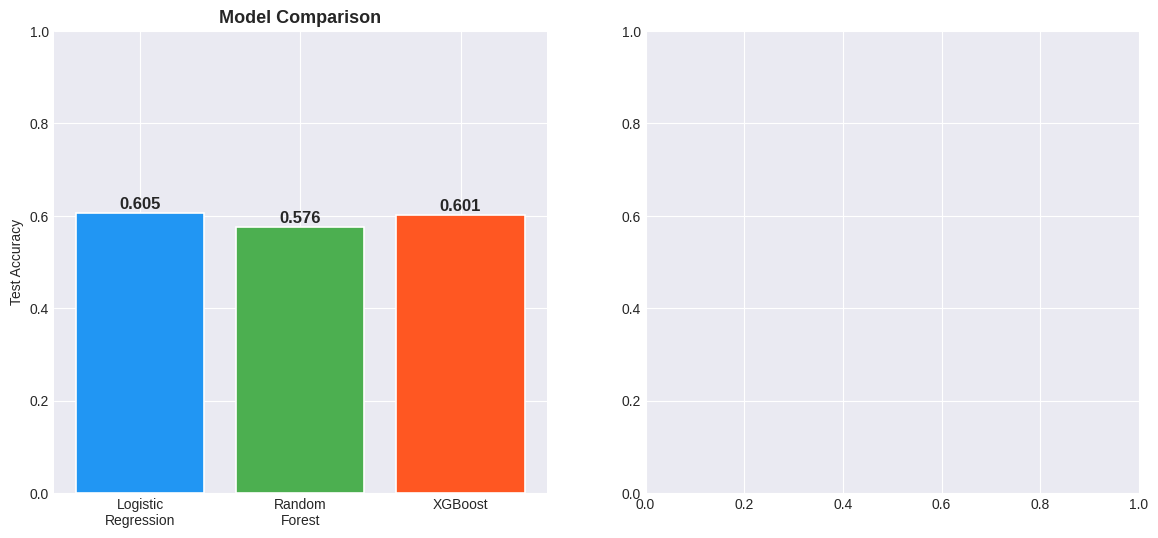

In [ ]:
# Plots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Model accuracy comparison
model_names = ['Logistic\nRegression', 'Random\nForest', 'XGBoost']
accs        = [lr_acc, rf_acc, xgb_acc]
bar_cols    = ['#2196F3', '#4CAF50', '#FF5722']
bars = ax1.bar(model_names, accs, color=bar_cols, edgecolor='white', linewidth=1.2)
ax1.set_ylim(0, 1.0)
ax1.set_ylabel('Test Accuracy')
ax1.set_title('Model Comparison', fontsize=13, fontweight='bold')
for bar, val in zip(bars, accs):
    ax1.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.01,
             f'{val:.3f}', ha='center', fontsize=12, fontweight='bold')

In [ ]:
# Feature importance
top10 = feat_imp.head(10)
ax2.barh(top10['Feature'][::-1], top10['Importance'][::-1], color='#FF9800')
ax2.set_xlabel('Importance Score')
ax2.set_title('XGBoost Feature Importance', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.savefig('model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: model_comparison.png")

# We use XGBoost for simulation — best at producing calibrated probabilities
SIM_MODEL = xgb
print(f"\nUsing XGBoost for the tournament simulation.")

<Figure size 640x480 with 0 Axes>

Saved: model_comparison.png

Using XGBoost for the tournament simulation.


## **TOURNAMENT SIMULATION SETUP**

HOW MONTE CARLO SIMULATION WORKS:
══════════════════════════════════════════════════════════════════
  1. Get win/draw/loss probabilities from XGBoost for each match
  2. Draw a random number between 0 and 1
  3. Use that to decide the outcome (weighted random)
     e.g., if p_home=0.45, p_draw=0.30, p_away=0.25:
       - Random draws 0.00–0.45 → home wins
       - Random draws 0.45–0.75 → draw
       - Random draws 0.75–1.00 → away wins
  4. Do this for EVERY match in the ENTIRE tournament
  5. Repeat 10,000 times
  6. Count how often each team wins = their probability

WHY 10,000 TIMES?
  One simulation is just one possible future.
  With 10,000, we get stable probability estimates.
  More simulations = more accurate (but slower).

2026 WORLD CUP FORMAT:
  → 48 teams in 12 groups of 4
  → Top 2 from each group = 24 teams advance
  → Best 8 of 12 third-place teams advance = 8 more
  → 32 teams total in Round of 32
  → Knockout: R32 → R16 → QF → SF → Final
"""


In [ ]:
# The simulation helper functions have been moved to cell JiarqMx2ob4D to ensure they are always in scope during the simulation.

In [ ]:
# CELL 10 — 🌍 DEFINE 2026 WORLD CUP GROUPS
# UPDATE THESE WITH THE ACTUAL DRAW / QUALIFIED TEAMS!

In [ ]:
# The WC2026_GROUPS and ALL_WC_TEAMS definitions have been moved to cell JiarqMx2ob4D to ensure they are always in scope during the simulation.
# DIAGNOSTIC CELL
all_ds_teams = set(df['home_team'].unique()) | set(df['away_team'].unique())

candidates = {
    'Czechia':                 ['Czech Republic', 'Czechia'],
    'Türkiye':                 ['Turkey', 'Türkiye', 'Turkiye'],
    'Curaçao':                 ['Curacao', 'Curaçao'],
    'Bosnia and Herzegovina':  ['Bosnia-Herzegovina', 'Bosnia and Herzegovina', 'Bosnia & Herzegovina'],
    'DR Congo':                ['DR Congo', 'Congo DR', 'Democratic Republic of the Congo'],
    'South Korea':             ['South Korea', 'Korea Republic', 'Korea DPR'],
    'Ivory Coast':             ['Ivory Coast', "Côte d'Ivoire", 'Cote d\'Ivoire'],
    'Cape Verde':              ['Cape Verde', 'Cabo Verde'],
    'United States':           ['United States', 'USA'],
}

print("Name check — pick whichever shows True:\n")
for wc_name, options in candidates.items():
    results = {o: (o in all_ds_teams) for o in options}
    correct = [k for k, v in results.items() if v]
    status = f"✅ use: '{correct[0]}'" if correct else "❌ NOT FOUND in dataset"
    print(f"  {wc_name:30s}  →  {status}")
    if not correct:
        # find closest match
        close = [t for t in all_ds_teams if any(p.lower() in t.lower() for p in wc_name.split())]
        if close: print(f"      Closest in dataset: {close[:3]}")

Name check — pick whichever shows True:

  Czechia                         →  ✅ use: 'Czech Republic'
  Türkiye                         →  ✅ use: 'Turkey'
  Curaçao                         →  ✅ use: 'Curaçao'
  Bosnia and Herzegovina          →  ✅ use: 'Bosnia and Herzegovina'
  DR Congo                        →  ✅ use: 'DR Congo'
  South Korea                     →  ✅ use: 'South Korea'
  Ivory Coast                     →  ✅ use: 'Ivory Coast'
  Cape Verde                      →  ✅ use: 'Cape Verde'
  United States                   →  ✅ use: 'United States'


In [ ]:
# CELL 10 — 🌍 DEFINE 2026 WORLD CUP GROUPS
WC2026_GROUPS = {
    'A': ['Mexico',         'South Korea',  'Czech Republic',        'South Africa'],
    'B': ['Canada',         'Switzerland',  'Qatar',                 'Bosnia-Herzegovina'],
    'C': ['Brazil',         'Morocco',      'Scotland',              'Haiti'],
    'D': ['United States',  'Australia',    'Turkey',                'Paraguay'],
    'E': ['Germany',        'Ivory Coast',  'Ecuador',               'Curacao'],
    'F': ['Netherlands',    'Japan',        'Sweden',                'Tunisia'],
    'G': ['Belgium',        'Egypt',        'Iran',                  'New Zealand'],
    'H': ['Spain',          'Uruguay',      'Saudi Arabia',          'Cape Verde'],
    'I': ['France',         'Senegal',      'Norway',                'Iraq'],
    'J': ['Argentina',      'Austria',      'Algeria',               'Jordan'],
    'K': ['Portugal',       'DR Congo',     'Uzbekistan',            'Colombia'],
    'L': ['England',        'Croatia',      'Ghana',                 'Panama'],
}

In [ ]:
from collections import defaultdict
import random
import numpy as np
import pandas as pd

# Define 2026 World Cup Groups
WC2026_GROUPS = {
    'A': ['Mexico', 'South Africa', 'South Korea', 'Czechia'],
    'B': ['Canada', 'Bosnia & Herzegovina', 'Qatar', 'Switzerland'],
    'C': ['Brazil', 'Morocco', 'Haiti', 'Scotland'],
    'D': ['United States', 'Paraguay', 'Australia', 'Turkey'],
    'E': ['Germany', 'Curacao', 'Ivory Coast', 'Ecuador'],
    'F': ['Netherlands', 'Japan', 'Sweden', 'Tunisia'],
    'G': ['Belgium', 'Egypt', 'Iran', 'New Zealand'],
    'H': ['Spain', 'Cape Verde', 'Saudi Arabia', 'Uruguay'],
    'I': ['France', 'Senegal', 'Iraq', 'Norway'],
    'J': ['Argentina', 'Algeria', 'Austria', 'Jordan'],
    'K': ['Portugal', 'DR Congo', 'Uzbekistan', 'Colombia'],
    'L': ['England', 'Croatia', 'Ghana', 'Panama']
}
ALL_WC_TEAMS = [t for grp in WC2026_GROUPS.values() for t in grp]
print(f"Total teams: {len(ALL_WC_TEAMS)}  (expected: 48)")



Total teams: 48  (expected: 48)


In [ ]:
# Sanity check: how many of these teams are in our Elo system?
# Ensure 'elo' is defined for this check, even if not fully populated yet.
# The full 'elo' dictionary should be populated by cell f2lc-RVXhzip.
if 'elo' not in globals():
    print("WARNING: 'elo' dictionary not found. Initializing with default Elo (1500) for sanity check. Please ensure cell f2lc-RVXhzip was executed.")
    elo = defaultdict(lambda: 1500)

in_elo  = [t for t in ALL_WC_TEAMS if t in elo]
not_elo = [t for t in ALL_WC_TEAMS if t not in elo]
print(f"Teams found in Elo system: {len(in_elo)}")
if not_elo:
    print(f"⚠️  Teams NOT in dataset (will use Elo=1500): {not_elo}")
    print("   → Check df['home_team'].unique() for correct spelling")

FEATURE_COLS = [
    'elo_diff', 'home_elo', 'away_elo',
    'home_win_rate', 'away_win_rate', 'win_rate_diff',
    'home_form', 'away_form', 'form_diff',
    'home_goals_scored', 'home_goals_conceded',
    'away_goals_scored', 'away_goals_conceded',
    'home_attack_vs_def', 'away_attack_vs_def',
    'is_neutral'
]


Teams found in Elo system: 45
⚠️  Teams NOT in dataset (will use Elo=1500): ['Czechia', 'Bosnia & Herzegovina', 'Curacao']
   → Check df['home_team'].unique() for correct spelling


In [ ]:
# Helper: get current stats for any team from our built history
def get_current_stats(team: str) -> dict:
    history = team_history[team]
    if not history:
        return {'win_rate': 0.50, 'form': 0.50, 'goals_scored': 1.20, 'goals_conceded': 1.20}

    recent_long  = history[-WINDOW_LONG:]
    recent_form  = history[-WINDOW_FORM:]
    recent_goals = history[-WINDOW_GOALS:]

    wins = sum(1 for g in recent_long if g['result'] == 'win')
    form_pts = sum(
        1.0 if g['result'] == 'win' else 0.5 if g['result'] == 'draw' else 0.0
        for g in recent_form
    )

    return {
        'win_rate':       wins / len(recent_long),
        'form':           form_pts / len(recent_form),
        'goals_scored':   float(np.mean([g['gf'] for g in recent_goals])),
        'goals_conceded': float(np.mean([g['ga'] for g in recent_goals]))
    }

def get_match_proba(team_a: str, team_b: str) -> tuple:
    """
    Predict probabilities for team_a vs team_b (neutral ground).
    Returns: (p_a_wins, p_draw, p_b_wins)
    """
    elo_a  = elo[team_a]
    elo_b  = elo[team_b]
    st_a   = get_current_stats(team_a)
    st_b   = get_current_stats(team_b)

    X_match = pd.DataFrame([{
        'elo_diff':            elo_a - elo_b,
        'home_elo':            elo_a,
        'away_elo':            elo_b,
        'home_win_rate':       st_a['win_rate'],
        'away_win_rate':       st_b['win_rate'],
        'win_rate_diff':       st_a['win_rate']     - st_b['win_rate'],
        'home_form':           st_a['form'],
        'away_form':           st_b['form'],
        'form_diff':           st_a['form']          - st_b['form'],
        'home_goals_scored':   st_a['goals_scored'],
        'home_goals_conceded': st_a['goals_conceded'],
        'away_goals_scored':   st_b['goals_scored'],
        'away_goals_conceded': st_b['goals_conceded'],
        'home_attack_vs_def':  st_a['goals_scored']  - st_b['goals_conceded'],
        'away_attack_vs_def':  st_b['goals_scored']  - st_a['goals_conceded'],
        'is_neutral':          1   # all WC matches are neutral
    }])[FEATURE_COLS]

    probs = SIM_MODEL.predict_proba(X_match)[0]
    # XGBoost classes: 0=away_win, 1=draw, 2=home_win
    return probs[2], probs[1], probs[0]

def sim_group_match(team_a: str, team_b: str) -> tuple:
    """
    Simulate one group stage match.
    Returns: (goals_a, goals_b)
    Uses Poisson-distributed goal counts adjusted to match the predicted winner.
    """
    p_a, p_draw, p_b = get_match_proba(team_a, team_b)
    r = random.random()

    if r < p_a:
        result = 'a_wins'
    elif r < p_a + p_draw:
        result = 'draw'
    else:
        result = 'b_wins'

    # Simulate realistic scoreline via Poisson distribution
    st_a = get_current_stats(team_a)
    st_b = get_current_stats(team_b)
    lambda_a = max(0.3, (st_a['goals_scored']  + st_b['goals_conceded']) / 2 * 0.75)
    lambda_b = max(0.3, (st_b['goals_scored']  + st_a['goals_conceded']) / 2 * 0.75)
    goals_a  = np.random.poisson(lambda_a)
    goals_b  = np.random.poisson(lambda_b)

    # Nudge goals to match predicted result
    if result == 'a_wins' and goals_a <= goals_b:
        goals_a = goals_b + random.randint(1, 2)
    elif result == 'b_wins' and goals_b <= goals_a:
        goals_b = goals_a + random.randint(1, 2)
    elif result == 'draw':
        g = min(goals_a, goals_b)
        goals_a = goals_b = g

    return int(goals_a), int(goals_b)

def sim_knockout_match(team_a: str, team_b: str) -> str:
    """
    Simulate a knockout match. Must return a winner (no draws).
    If draw in 90 min → penalty shootout (50/50 + slight Elo edge).
    """
    p_a, p_draw, p_b = get_match_proba(team_a, team_b)
    r = random.random()

    if r < p_a:
        return team_a
    elif r < p_a + p_draw:
        # Penalties — slight Elo advantage
        elo_a, elo_b = elo[team_a], elo[team_b]
        p_pens = 0.50 + (elo_a - elo_b) / 5000
        p_pens = float(np.clip(p_pens, 0.30, 0.70))
        return team_a if random.random() < p_pens else team_b
    else:
        return team_b

def simulate_group(teams: list) -> tuple:
    """
    Simulate one group (round-robin: everyone plays everyone once).
    Returns: (teams sorted by standing, standings dict)
    """
    stnd = {t: {'pts': 0, 'gf': 0, 'ga': 0, 'gd': 0} for t in teams}

    for i in range(len(teams)):
        for j in range(i + 1, len(teams)):
            a, b   = teams[i], teams[j]
            ga, gb = sim_group_match(a, b)

            stnd[a]['gf'] += ga; stnd[a]['ga'] += gb; stnd[a]['gd'] += ga - gb
            stnd[b]['gf'] += gb; stnd[b]['ga'] += ga; stnd[b]['gd'] += gb - ga

            if ga > gb:
                stnd[a]['pts'] += 3
            elif ga == gb:
                stnd[a]['pts'] += 1; stnd[b]['pts'] += 1
            else:
                stnd[b]['pts'] += 3

    sorted_teams = sorted(
        teams,
        key=lambda t: (stnd[t]['pts'], stnd[t]['gd'], stnd[t]['gf']),
        reverse=True
    )
    return sorted_teams, stnd

In [ ]:
import itertools, time, random
import pandas as pd
import numpy as np
from collections import defaultdict

# -- Ensure global context variables are ready --
# These should exist from previous cells, but we'll safeguard the logic
if 'team_history' not in globals():
    print("⚠️ team_history not found. Please ensure cell 6bg886gskQfG and sDEy8eqLkeB_ were executed.")

# -- Ensure Helper Functions are defined in this scope --
def get_current_stats(team: str) -> dict:
    # Accessing the global team_history dictionary
    history = team_history.get(team, [])
    if not history:
        return {'win_rate': 0.50, 'form': 0.50, 'goals_scored': 1.20, 'goals_conceded': 1.20}

    # Use the same logic defined in earlier cells
    recent_long  = history[-15:]
    recent_form  = history[-5:]
    recent_goals = history[-10:]

    wins = sum(1 for g in recent_long if g['result'] == 'win')
    form_pts = sum(1.0 if g['result'] == 'win' else 0.5 if g['result'] == 'draw' else 0.0 for g in recent_form)

    return {
        'win_rate': wins / len(recent_long) if recent_long else 0.5,
        'form': form_pts / len(recent_form) if recent_form else 0.5,
        'goals_scored': float(np.mean([g['gf'] for g in recent_goals])) if recent_goals else 1.2,
        'goals_conceded': float(np.mean([g['ga'] for g in recent_goals])) if recent_goals else 1.2
    }

def simulate_group(teams: list) -> tuple:
    stnd = {t: {'pts': 0, 'gf': 0, 'ga': 0, 'gd': 0} for t in teams}
    for i in range(len(teams)):
        for j in range(i + 1, len(teams)):
            a, b = teams[i], teams[j]
            p_a, p_draw, p_b = MATCH_PROBA.get((a, b), (0.33, 0.34, 0.33))
            r = random.random()
            # Simplified scoring for simulation speed
            if r < p_a: ga, gb = 2, 1
            elif r < p_a + p_draw: ga, gb = 1, 1
            else: ga, gb = 1, 2

            stnd[a]['gf'] += ga; stnd[a]['ga'] += gb; stnd[a]['gd'] += ga - gb
            stnd[b]['gf'] += gb; stnd[b]['ga'] += ga; stnd[b]['gd'] += gb - ga
            if ga > gb: stnd[a]['pts'] += 3
            elif ga == gb: stnd[a]['pts'] += 1; stnd[b]['pts'] += 1
            else: stnd[b]['pts'] += 3

    return sorted(teams, key=lambda t: (stnd[t]['pts'], stnd[t]['gd'], stnd[t]['gf']), reverse=True), stnd

def sim_knockout_match(team_a: str, team_b: str) -> str:
    p_a, p_draw, p_b = MATCH_PROBA.get((team_a, team_b), (0.33, 0.34, 0.33))
    r = random.random()
    if r < p_a: return team_a
    elif r < p_a + p_draw:
        elo_a, elo_b = TEAM_ELOS.get(team_a, 1500), TEAM_ELOS.get(team_b, 1500)
        return team_a if random.random() < (0.5 + (elo_a - elo_b) / 5000) else team_b
    else: return team_b

# -- Step 1: Pre-compute stats --
ALL_WC_TEAMS = [t for grp in WC2026_GROUPS.values() for t in grp]
print("⚙️ Pre-computing team stats...")
TEAM_STATS = {team: get_current_stats(team) for team in ALL_WC_TEAMS}
TEAM_ELOS  = {team: elo.get(team, 1500.0) for team in ALL_WC_TEAMS}

# -- Step 2: Batch-predict probabilities --
print("⚙️ Batch-predicting matchup probabilities...")
all_pairs = list(itertools.combinations(ALL_WC_TEAMS, 2))
batch_rows = []
for ta, tb in all_pairs:
    sa, sb, ea, eb = TEAM_STATS[ta], TEAM_STATS[tb], TEAM_ELOS[ta], TEAM_ELOS[tb]
    batch_rows.append({'elo_diff': ea-eb, 'home_elo': ea, 'away_elo': eb, 'home_win_rate': sa['win_rate'], 'away_win_rate': sb['win_rate'], 'win_rate_diff': sa['win_rate']-sb['win_rate'], 'home_form': sa['form'], 'away_form': sb['form'], 'form_diff': sa['form']-sb['form'], 'home_goals_scored': sa['goals_scored'], 'home_goals_conceded': sa['goals_conceded'], 'away_goals_scored': sb['goals_scored'], 'away_goals_conceded': sb['goals_conceded'], 'home_attack_vs_def': sa['goals_scored']-sb['goals_conceded'], 'away_attack_vs_def': sb['goals_scored']-sa['goals_conceded'], 'is_neutral': 1})

X_batch = pd.DataFrame(batch_rows)[FEATURE_COLS]
probs_matrix = SIM_MODEL.predict_proba(X_batch)
MATCH_PROBA = {}
for (ta, tb), p in zip(all_pairs, probs_matrix):
    # Index mapping: 0=away_win, 1=draw, 2=home_win
    MATCH_PROBA[(ta, tb)] = (p[2], p[1], p[0])
    MATCH_PROBA[(tb, ta)] = (p[0], p[1], p[2])

# -- Step 4: 10,000 Simulations --
N_SIMS = 10000
win_counter, final_counter, sf_counter, qf_counter, r16_counter, r32_counter, group_exit_counter = [defaultdict(int) for _ in range(7)]

print(f"⚽ Running {N_SIMS:,} simulations...")
for sim in range(N_SIMS):
    group_1st, group_2nd, group_3rd = [], [], []
    for teams in WC2026_GROUPS.values():
        sorted_t, _ = simulate_group(teams)
        group_1st.append(sorted_t[0]); group_2nd.append(sorted_t[1]); group_3rd.append(sorted_t[2])

    best_3rd = sorted(group_3rd, key=lambda t: TEAM_ELOS.get(t, 1500), reverse=True)[:8]
    r32_teams = group_1st + group_2nd + best_3rd

    for t in ALL_WC_TEAMS:
        if t not in r32_teams: group_exit_counter[t] += 1
        else: r32_counter[t] += 1

    random.shuffle(r32_teams)
    r16 = [sim_knockout_match(r32_teams[i], r32_teams[i+1]) for i in range(0, 32, 2)]
    for t in r16: r16_counter[t] += 1
    qf = [sim_knockout_match(r16[i], r16[i+1]) for i in range(0, 16, 2)]
    for t in qf: qf_counter[t] += 1
    sf = [sim_knockout_match(qf[i], qf[i+1]) for i in range(0, 8, 2)]
    for t in sf: sf_counter[t] += 1
    f = [sim_knockout_match(sf[i], sf[i+1]) for i in range(0, 4, 2)]
    for t in f: final_counter[t] += 1
    win_counter[sim_knockout_match(f[0], f[1])] += 1

    if (sim+1) % 2500 == 0: print(f"   [{(sim+1)/N_SIMS*100:3.0f}%] done")

print("\n✅ Done!")

⚙️ Pre-computing team stats...
⚙️ Batch-predicting matchup probabilities...
⚽ Running 10,000 simulations...
   [ 25%] done
   [ 50%] done
   [ 75%] done
   [100%] done

✅ Done!


═════════════════════════════════════════════
   TOP 15 WORLD CUP PREDICTIONS
═════════════════════════════════════════════
           Team  WINNER %  Finalist %  Semi-Final %  Group Exit %
1     Argentina     15.24       24.01         36.14          2.33
2       England     13.76       22.48         33.89          1.27
3         Spain     12.59       20.66         33.18          0.31
4        France      9.89       17.20         28.73          3.57
5       Germany      6.79       12.98         23.90          0.60
6        Norway      6.17       11.52         20.50         10.71
7      Colombia      4.92       10.42         19.33          8.10
8   Netherlands      4.81       10.39         20.21          3.21
9        Brazil      4.69        9.91         18.88          2.58
10     Portugal      2.49        6.17         13.96          4.37
11      Belgium      2.39        5.62         12.94          6.02
12      Croatia      1.95        4.59         11.01          5.67
13        Japan   

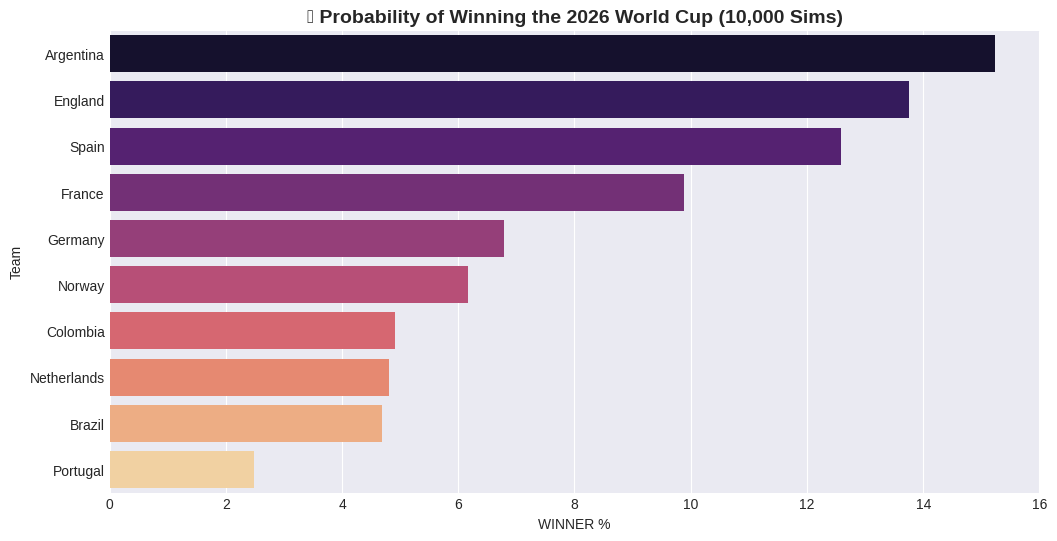

In [ ]:
# ─── ANALYZE & VISUALIZE RESULTS ───
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sim_results = pd.DataFrame([{
    'Team': t,
    'WINNER %': (win_counter[t] / N_SIMS) * 100,
    'Finalist %': (final_counter[t] / N_SIMS) * 100,
    'Semi-Final %': (sf_counter[t] / N_SIMS) * 100,
    'Group Exit %': (group_exit_counter[t] / N_SIMS) * 100
} for t in ALL_WC_TEAMS])

sim_results = sim_results.sort_values('WINNER %', ascending=False).reset_index(drop=True)
sim_results.index += 1

print("═" * 45)
print("   TOP 15 WORLD CUP PREDICTIONS")
print("═" * 45)
print(sim_results.head(15).to_string())

plt.figure(figsize=(12, 6))
sns.barplot(x='WINNER %', y='Team', data=sim_results.head(10), palette='magma')
plt.title('⚽ Probability of Winning the 2026 World Cup (10,000 Sims)', fontsize=14, fontweight='bold')
plt.show()

RESULTS & VISUALIZATION


══════════════════════════════════════════════════════════════════════
  🏆  WORLD CUP 2026 — PREDICTIONS  (10,000 simulations)
══════════════════════════════════════════════════════════════════════
                Team    Elo  Win%  Final%  Semi%   QF%  R16%  GroupExit%
           Argentina 2057.0 15.24   24.01  36.14 52.90 73.42        2.33
             England 2019.0 13.76   22.48  33.89 50.16 71.34        1.27
               Spain 2074.0 12.59   20.66  33.18 50.80 72.93        0.31
              France 2032.0  9.89   17.20  28.73 44.67 67.44        3.57
             Germany 1959.0  6.79   12.98  23.90 40.38 64.74        0.60
              Norway 1903.0  6.17   11.52  20.50 35.13 57.47       10.71
            Colombia 1948.0  4.92   10.42  19.33 35.02 58.14        8.10
         Netherlands 1929.0  4.81   10.39  20.21 35.74 60.13        3.21
              Brazil 1937.0  4.69    9.91  18.88 34.51 59.78        2.58
            Portugal 1919.0  2.49    6.17  13.96 28.44 53.99        4.3

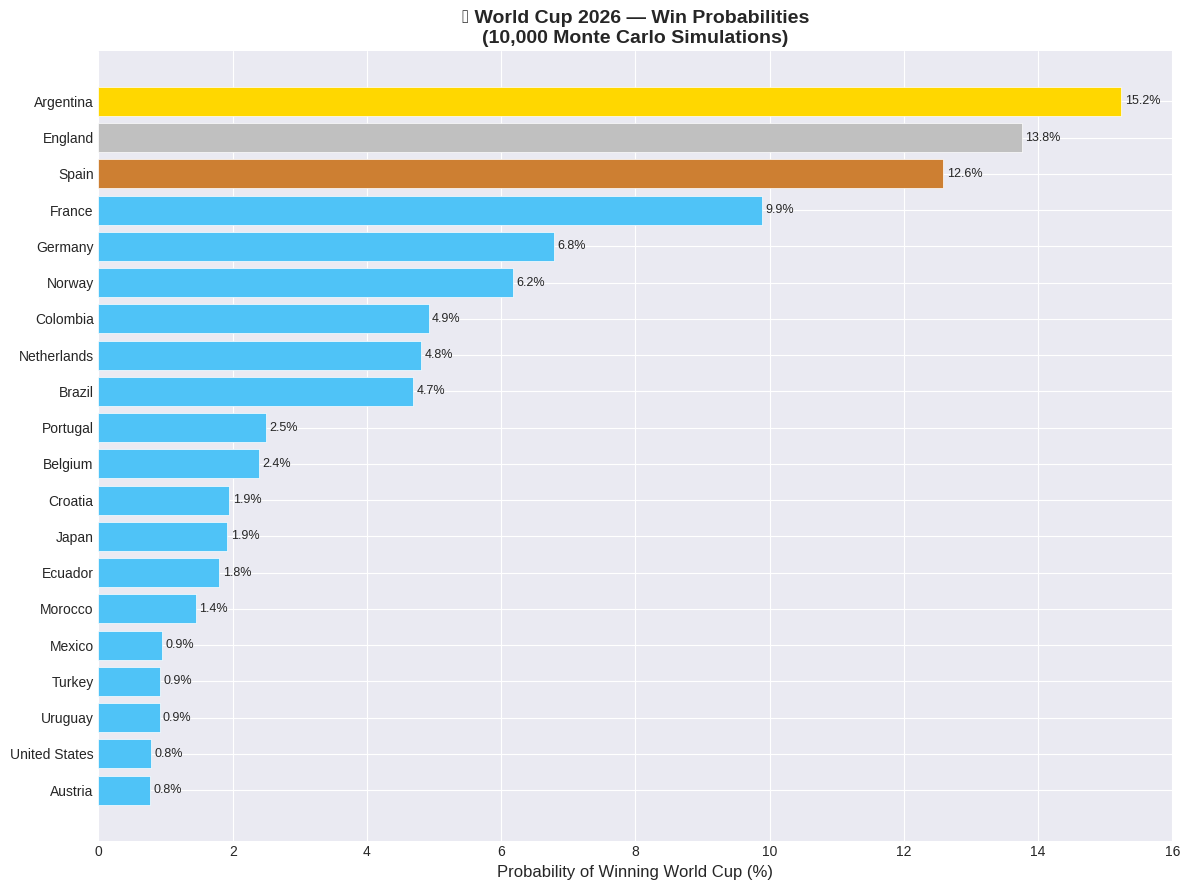

Saved: win_probabilities.png


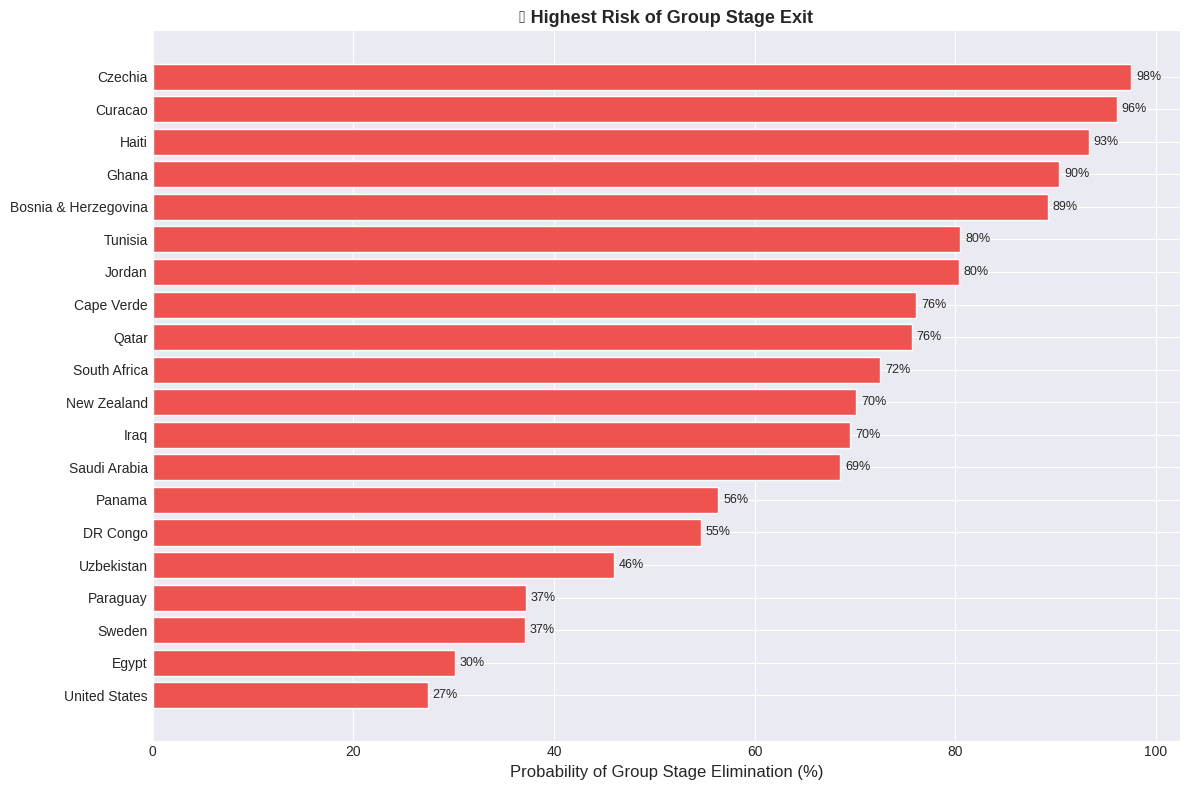

Saved: group_exit_risk.png


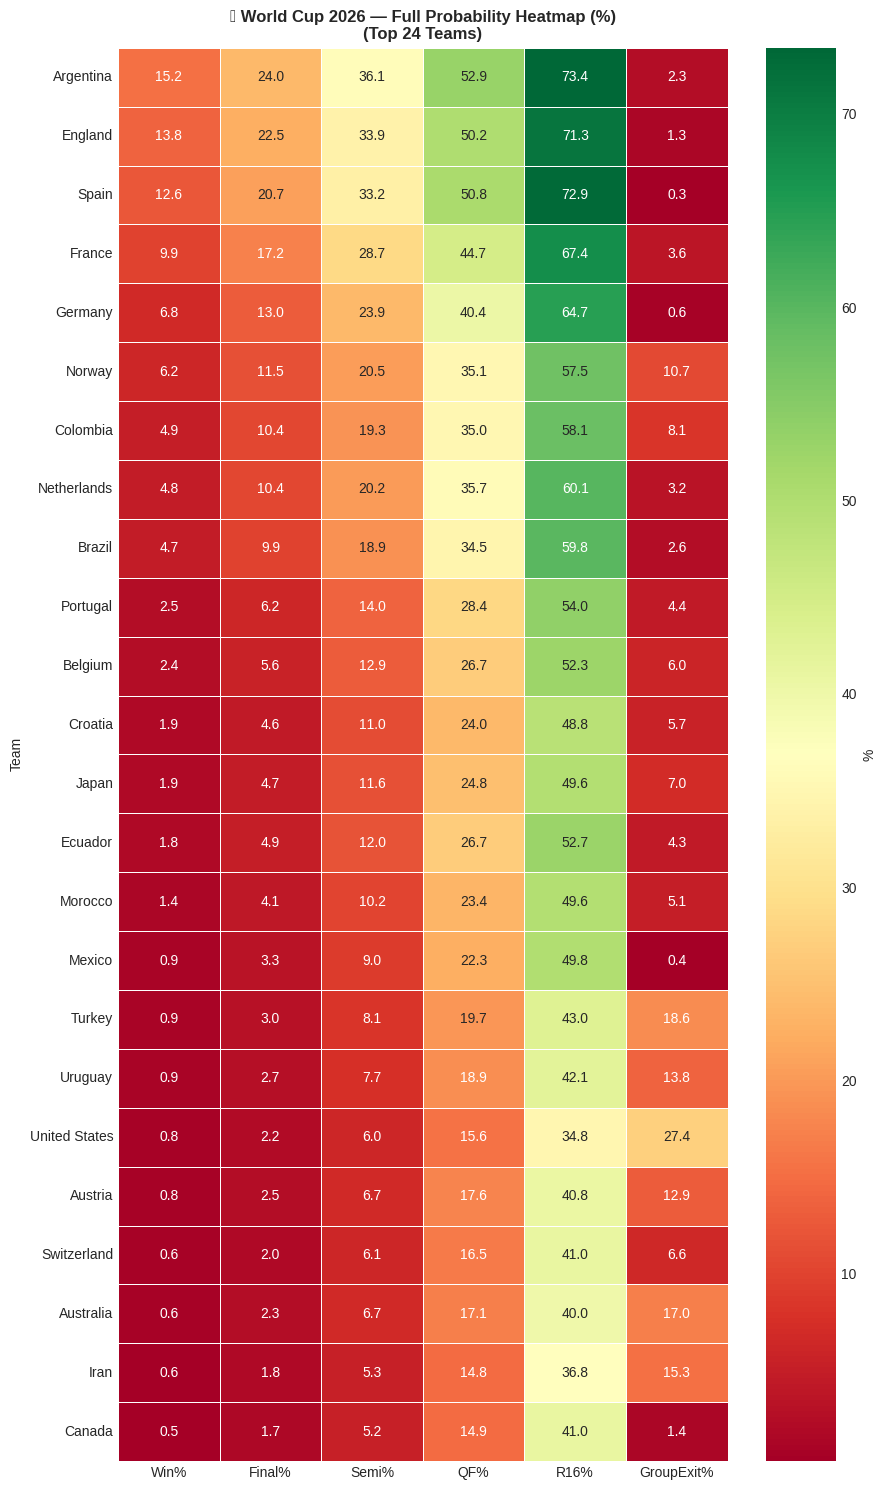

Saved: probability_heatmap.png

    ALL OUTPUT FILES SAVED:
  ├── elo_ratings.png
  ├── model_comparison.png
  ├── win_probabilities.png
  ├── group_exit_risk.png
  └── probability_heatmap.png

Remember:
  → Football is beautifully unpredictable. And even I think this is a shit prediction as a Ronaldo fan!


In [40]:
# Build results summary
results_df = pd.DataFrame([
    {
        'Team':          t,
        'Elo':           round(elo.get(t, 1500), 0),
        'Win%':          round(win_counter[t]        / N_SIMS * 100, 2),
        'Final%':        round(final_counter[t]      / N_SIMS * 100, 2),
        'Semi%':         round(sf_counter[t]         / N_SIMS * 100, 2),
        'QF%':           round(qf_counter[t]         / N_SIMS * 100, 2),
        'R16%':          round(r16_counter[t]        / N_SIMS * 100, 2),
        'GroupExit%':    round(group_exit_counter[t] / N_SIMS * 100, 2),
    }
    for t in ALL_WC_TEAMS
]).sort_values('Win%', ascending=False).reset_index(drop=True)

print("\n" + "═" * 70)
print("  🏆  WORLD CUP 2026 — PREDICTIONS  (10,000 simulations)")
print("═" * 70)
print(results_df.to_string(index=False))
print("═" * 70)

# ── Plot 1: Win Probabilities (top 20) ──────────────────────
fig, ax = plt.subplots(figsize=(12, 9))
top20 = results_df.head(20)
medal_colors = ['gold', 'silver', '#cd7f32'] + ['#4fc3f7'] * 17

bars = ax.barh(
    top20['Team'][::-1],
    top20['Win%'][::-1],
    color=medal_colors[::-1],
    edgecolor='white',
    linewidth=0.5
)
ax.set_xlabel('Probability of Winning World Cup (%)', fontsize=12)
ax.set_title(
    '🏆 World Cup 2026 — Win Probabilities\n(10,000 Monte Carlo Simulations)',
    fontsize=14, fontweight='bold'
)
for bar, val in zip(bars, top20['Win%'][::-1]):
    ax.text(bar.get_width() + 0.05, bar.get_y() + bar.get_height() / 2,
            f'{val:.1f}%', va='center', fontsize=9)
plt.tight_layout()
plt.savefig('win_probabilities.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: win_probabilities.png")

# ── Plot 2: Group Stage Exit Risk ───────────────────────────
fig, ax = plt.subplots(figsize=(12, 8))
exit_sorted = results_df.sort_values('GroupExit%', ascending=True).tail(20)
bars = ax.barh(exit_sorted['Team'], exit_sorted['GroupExit%'], color='#ef5350', edgecolor='white')
ax.set_xlabel('Probability of Group Stage Elimination (%)', fontsize=12)
ax.set_title('❌ Highest Risk of Group Stage Exit', fontsize=13, fontweight='bold')
for bar, val in zip(bars, exit_sorted['GroupExit%']):
    ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height() / 2,
            f'{val:.0f}%', va='center', fontsize=9)
plt.tight_layout()
plt.savefig('group_exit_risk.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: group_exit_risk.png")

# ── Plot 3: Full Probability Heatmap ────────────────────────
fig, ax = plt.subplots(figsize=(9, 15))
heat_cols = ['Win%', 'Final%', 'Semi%', 'QF%', 'R16%', 'GroupExit%']
heat_data = results_df[['Team'] + heat_cols].head(24).set_index('Team')

sns.heatmap(
    heat_data,
    annot=True, fmt='.1f',
    cmap='RdYlGn',
    linewidths=0.4,
    ax=ax,
    cbar_kws={'label': '%'}
)
ax.set_title(
    '🌍 World Cup 2026 — Full Probability Heatmap (%)\n(Top 24 Teams)',
    fontsize=12, fontweight='bold'
)
plt.tight_layout()
plt.savefig('probability_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: probability_heatmap.png")

# ── Summary print ────────────────────────────────────────────
print("\n" + "=" * 45)
print("    ALL OUTPUT FILES SAVED:")
print("  ├── elo_ratings.png")
print("  ├── model_comparison.png")
print("  ├── win_probabilities.png")
print("  ├── group_exit_risk.png")
print("  └── probability_heatmap.png")
print("=" * 45)
print("\nRemember:")
print("  → Football is beautifully unpredictable. And even I think this is a shit prediction as a Ronaldo fan!")